In [ ]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


def _circle_intersection_area(r1, r2, d):
    """Intersection area of two circles with radii r1, r2 and center distance d."""
    if d >= r1 + r2:
        return 0.0
    if d <= abs(r1 - r2):
        return math.pi * min(r1, r2) ** 2
    cos_a = (d**2 + r1**2 - r2**2) / (2 * d * r1)
    cos_b = (d**2 + r2**2 - r1**2) / (2 * d * r2)
    alpha = 2 * math.acos(max(-1.0, min(1.0, cos_a)))
    beta  = 2 * math.acos(max(-1.0, min(1.0, cos_b)))
    return 0.5 * (r1**2 * (alpha - math.sin(alpha)) + r2**2 * (beta - math.sin(beta)))


def _dist_for_area(r1, r2, target):
    """Center distance that yields the given intersection area (bisection)."""
    max_area = math.pi * min(r1, r2) ** 2
    if target <= 0:
        return r1 + r2 + 1e-6
    if target >= max_area:
        return abs(r1 - r2)
    lo, hi = abs(r1 - r2), r1 + r2
    for _ in range(64):
        mid = 0.5 * (lo + hi)
        if _circle_intersection_area(r1, r2, mid) < target:
            hi = mid
        else:
            lo = mid
    return 0.5 * (lo + hi)


def draw_nested_venn(
    nA, nB, nC, nD,
    nAB, nAC, nBC, nABC,
    labels=("A", "B", "C", "D"),
):
    """
    Draw a 4-set Venn-like diagram where D contains A, B, and C.
    Circle areas and overlap regions are proportional to the set counts.
    Parameters:
        nA, nB, nC, nD: counts for sets A, B, C, and D (D should be ≥ union of A,B,C)
        nAB, nAC, nBC: counts for pairwise intersections of A&B, A&C, B&C
        nABC: count for triple intersection of A, B, and C
        labels: optional 4-tuple of set labels (default: "A", "B", "C", "D")
    """
    A, B, C, D = labels

    onlyA   = nA - nAB - nAC + nABC
    onlyB   = nB - nAB - nBC + nABC
    onlyC   = nC - nAC - nBC + nABC
    onlyAB  = nAB - nABC
    onlyAC  = nAC - nABC
    onlyBC  = nBC - nABC
    onlyABC = nABC
    onlyD   = nD - (nA + nB + nC - nAB - nAC - nBC + nABC)

    bad = {k: v for k, v in {
        "onlyA": onlyA, "onlyB": onlyB, "onlyC": onlyC,
        "onlyAB": onlyAB, "onlyAC": onlyAC, "onlyBC": onlyBC,
        "onlyABC": onlyABC, "onlyD": onlyD,
    }.items() if v < 0}
    if bad:
        raise ValueError(f"Inconsistent counts — negative regions: {bad}")

    # Proportional radii: area ∝ count → radius ∝ √count
    R_D   = 3.5
    scale = R_D / math.sqrt(nD)
    r_A   = scale * math.sqrt(nA)
    r_B   = scale * math.sqrt(nB)
    r_C   = scale * math.sqrt(nC)

    # Solve for pairwise center distances so intersection areas ∝ counts
    k    = math.pi * scale**2   # diagram area per item
    d_AB = _dist_for_area(r_A, r_B, k * nAB)
    d_AC = _dist_for_area(r_A, r_C, k * nAC)
    d_BC = _dist_for_area(r_B, r_C, k * nBC)

    # Place A at origin, B on +x axis, trilaterate C below the AB axis
    xA, yA = 0.0, 0.0
    xB, yB = d_AB, 0.0
    xC = (d_AC**2 - d_BC**2 + d_AB**2) / (2 * d_AB) if d_AB > 1e-9 else 0.0
    yC = -math.sqrt(max(0.0, d_AC**2 - xC**2))

    # Centre the cluster at the origin
    mx = (xA + xB + xC) / 3.0;  my = (yA + yB + yC) / 3.0
    xA -= mx; yA -= my
    xB -= mx; yB -= my
    xC -= mx; yC -= my

    # D must encompass all inner circles; expand if needed
    r_D = max(R_D,
              max(math.hypot(xA, yA) + r_A,
                  math.hypot(xB, yB) + r_B,
                  math.hypot(xC, yC) + r_C) * 1.08)

    # ── Figure ────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.set_aspect("equal")
    ax.axis("off")

    ax.add_patch(Circle((0, 0), r_D,
                         edgecolor="#2ca02c", facecolor="#ffffff", alpha=0.35, lw=2))
    ax.add_patch(Circle((xA, yA), r_A,
                         edgecolor="#1f77b4", facecolor="#1f77b4", alpha=0.25, lw=2))
    ax.add_patch(Circle((xB, yB), r_B,
                         edgecolor="#e7d809ff", facecolor="#e7d809ff", alpha=0.25, lw=2))
    ax.add_patch(Circle((xC, yC), r_C,
                         edgecolor="#959795", facecolor="#959795", alpha=0.25, lw=2))

    # ── Set labels (outward from the cluster centroid) ─────────────────────
    def _outward(x, y, r, frac=1.25):
        d = math.hypot(x, y)
        if d < 1e-9:
            return x, y + r * frac
        return x + x / d * r * frac, y + y / d * r * frac

    ax.text(*_outward(xA, yA, r_A), A, fontsize=13, weight="bold",
            color="#1f77b4", ha="center", va="center")
    ax.text(*_outward(xB, yB, r_B), B, fontsize=13, weight="bold",
            color="#e7d809ff", ha="center", va="center")
    ax.text(*_outward(xC, yC, r_C), C, fontsize=13, weight="bold",
            color="#959795", ha="center", va="center")
    ax.text(0, r_D + 0.25, D, fontsize=13, weight="bold", ha="center", va="center")

    # ── Region count labels ────────────────────────────────────────────────
    def _exclusive_pos(xa, ya, ra, xb, yb, xc, yc, frac=0.6):
        """Position inside (xa,ya,ra) pushed away from the other two centres."""
        tx = (xb + xc) / 2;  ty = (yb + yc) / 2
        dx = xa - tx;         dy = ya - ty
        mag = math.hypot(dx, dy)
        if mag < 1e-9:
            return xa, ya
        return xa + dx / mag * ra * frac, ya + dy / mag * ra * frac

    ax.text(*_exclusive_pos(xA, yA, r_A, xB, yB, xC, yC),
            str(onlyA), fontsize=11, ha="center", va="center")
    ax.text(*_exclusive_pos(xB, yB, r_B, xA, yA, xC, yC),
            str(onlyB), fontsize=11, ha="center", va="center")
    ax.text(*_exclusive_pos(xC, yC, r_C, xA, yA, xB, yB),
            str(onlyC), fontsize=11, ha="center", va="center")

    ax.text((xA + xB) / 2, (yA + yB) / 2, str(onlyAB),
            fontsize=11, ha="center", va="center")
    ax.text((xA + xC) / 2, (yA + yC) / 2, str(onlyAC),
            fontsize=11, ha="center", va="center")
    ax.text((xB + xC) / 2, (yB + yC) / 2, str(onlyBC),
            fontsize=11, ha="center", va="center")
    ax.text(0, 0, str(onlyABC),
            fontsize=11, ha="center", va="center", weight="bold")

    # D-only label: above the inner circles, inside D
    top_inner = max(yA + r_A, yB + r_B, yC + r_C) + 0.3
    d_only_y  = max(top_inner, r_D * 0.65)
    ax.text(0, d_only_y, f"{D} only: {onlyD}",
            fontsize=11, ha="center", va="center")

    lim = r_D + 0.6
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    plt.tight_layout()
    plt.show()


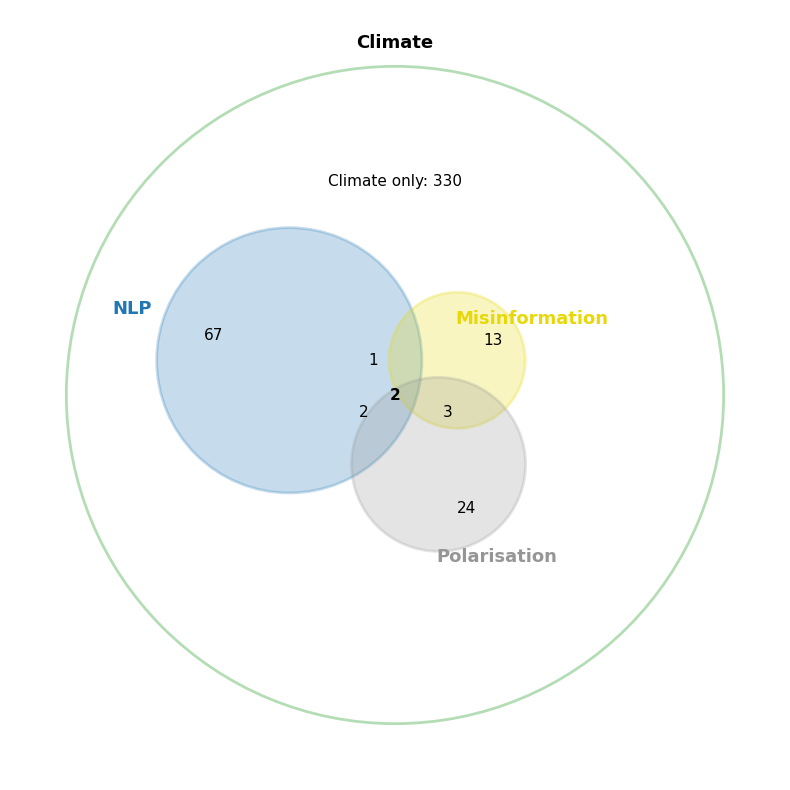

In [ ]:
# Surveys from WIREs Climate Change
draw_nested_venn(
    nA=72, nB=19, nC=31, nD=442,
    nAB=3, nAC=4, nBC=5, nABC=2,
    labels=("NLP", "Misinformation", "Polarisation", "Climate")
)

In [14]:
# Semantic Scholar test

import json
import requests

# Define the bulk search endpoint
url = "https://api.semanticscholar.org/graph/v1/paper/search/bulk"

# Set up your query parameters
query_params = {
    # Wrapping the phrase in quotes ensures it looks for the exact phrase
    "query": 'polarisation + polarization',
    "year": "2020",
    # Specifying fields is highly recommended to keep payload sizes manageable
    "fields": "paperId,externalIds,title,year,abstract"
    # "fields": "paperId,externalIds,title,year,publicationDate,abstract,publicationVenue,journal,citationCount,s2FieldsOfStudy,publicationTypes,authors"
}

# Optional: Add your API key if you have one to avoid rate limits
# headers = {"x-api-key": "YOUR_API_KEY_HERE"}

try:
    response = requests.get(url, params=query_params)  # add headers=headers if using a key
    response.raise_for_status()

    # Parse and print the JSON response
    data = response.json()
    print(json.dumps(data, indent=2))

except requests.exceptions.HTTPError as err:
    print(f"HTTP Error: {err}")
except Exception as e:
    print(f"An error occurred: {e}")

{
  "total": 115,
  "token": null,
  "data": [
    {
      "paperId": "01e9fcd0b33f4e85297aeb39ca5ba6c90a33a114",
      "externalIds": {
        "MAG": "3109183785",
        "DOI": "10.3390/met10121583",
        "CorpusId": 229443503
      },
      "title": "In-Vitro Degradation of Hollow Silica Reinforced Magnesium Syntactic Foams in Different Simulated Body Fluids for Biomedical Applications",
      "year": 2020,
      "openAccessPdf": {
        "url": "https://www.mdpi.com/2075-4701/10/12/1583/pdf?version=1606391916",
        "status": "GOLD",
        "license": "CCBY",
        "disclaimer": "Notice: Paper or abstract available at https://api.unpaywall.org/v2/10.3390/met10121583?email=<INSERT_YOUR_EMAIL> or https://doi.org/10.3390/met10121583, which is subject to the license by the author or copyright owner provided with this content. Please go to the source to verify the license and copyright information for your use."
      },
      "authors": [
        {
          "authorId": "22

In [15]:
len(data['data'])

115